<a href="https://colab.research.google.com/github/jelvalojel-glitch/ML_task_09/blob/main/task09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

from sklearn.datasets import make_moons

# Загрузка датасета
uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
display(df.head())

# Удаляем идентификатор и отделяем целевую переменную
X = df.drop(columns=["stroke", "id"])
y = df["stroke"]

# Определяем типы признаков
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numeric features:", list(numeric_features))
print("Categorical features:", list(categorical_features))

# Разделение данных
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv
Dataset shape: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


Numeric features: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
Categorical features: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']
Training set: (4088, 10)
Testing set: (1022, 10)


In [2]:
# Обработка числовых признаков
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Обработка категориальных признаков
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Объединение обработки
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Общий Pipeline
svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("scaler", StandardScaler(with_mean=False)),
    ("svc", SVC(
        kernel="rbf",
        class_weight="balanced",
        cache_size=1000
    ))
])

# Сетка гиперпараметров
param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__gamma": ["scale", 0.01, 0.1, 1]
}

# Кросс-валидация
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    svm_pipeline,
    param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

# Обучение
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV F1-score:", grid_search.best_score_)

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best parameters: {'svc__C': 1, 'svc__gamma': 0.01}
Best CV F1-score: 0.2162788077952447


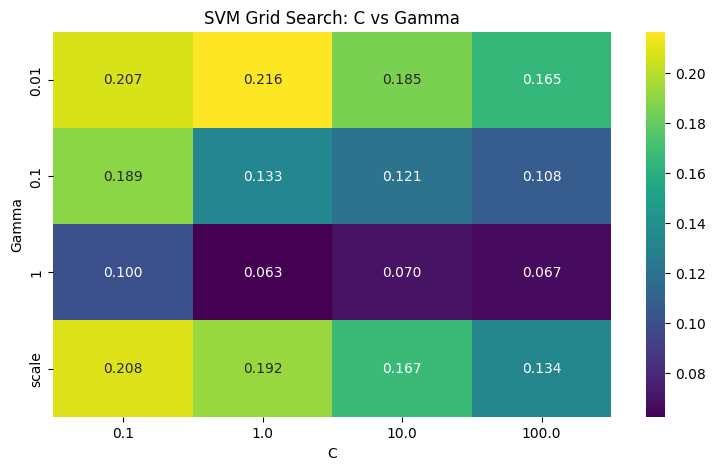

In [3]:
results = pd.DataFrame(grid_search.cv_results_)

heatmap_data = results.pivot(
    index="param_svc__gamma",
    columns="param_svc__C",
    values="mean_test_score"
)

plt.figure(figsize=(9, 5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="viridis"
)

plt.title("SVM Grid Search: C vs Gamma")
plt.xlabel("C")
plt.ylabel("Gamma")

plt.show()

In [4]:
import time

# Лучшая RBF-модель
best_svm = grid_search.best_estimator_

# Линейная SVM
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("scaler", StandardScaler(with_mean=False)),
    ("svc", SVC(
        kernel="linear",
        class_weight="balanced",
        cache_size=1000
    ))
])

linear_search = GridSearchCV(
    linear_pipeline,
    {"svc__C": [0.1, 1, 10, 100]},
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

start_time = time.time()
linear_search.fit(X_train, y_train)
linear_time = time.time() - start_time

best_linear = linear_search.best_estimator_

# Функция оценки моделей
def evaluate_model(model, X_test, y_test, name):
    predictions = model.predict(X_test)
    scores = model.decision_function(X_test)

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, scores)
    }

# Оценка SVM
rbf_metrics = evaluate_model(
    best_svm, X_test, y_test, "SVM RBF"
)

linear_metrics = evaluate_model(
    best_linear, X_test, y_test, "SVM Linear"
)

# Результаты предыдущих практических работ
previous_results = [
    {
        "Model": "Random Forest (PR-7)",
        "Accuracy": 0.860,
        "Precision": 0.79,
        "Recall": 0.59,
        "F1-score": 0.67,
        "ROC-AUC": np.nan
    },
    {
        "Model": "Gradient Boosting (PR-8)",
        "Accuracy": 0.8636,
        "Precision": 0.77,
        "Recall": 0.64,
        "F1-score": 0.70,
        "ROC-AUC": np.nan
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.8175,
        "Precision": np.nan,
        "Recall": np.nan,
        "F1-score": np.nan,
        "ROC-AUC": np.nan
    }
]

comparison = pd.DataFrame(
    previous_results + [rbf_metrics, linear_metrics]
)

print("Model comparison:")
display(comparison.round(4))

print("\nBest RBF parameters:", grid_search.best_params_)
print("Best Linear C:", linear_search.best_params_)

print("\nRBF classification report:")
print(classification_report(
    y_test,
    best_svm.predict(X_test)
))

print("Linear SVM classification report:")
print(classification_report(
    y_test,
    best_linear.predict(X_test)
))

# Приблизительное время Grid Search для RBF
rbf_cv_time = (
    results["mean_fit_time"].sum() * cv.get_n_splits()
)

print("\nRBF Grid Search CV time (approx.):",
      round(rbf_cv_time, 2), "seconds")

print("RBF final refit time:",
      round(grid_search.refit_time_, 2), "seconds")

print("Linear Grid Search time:",
      round(linear_time, 2), "seconds")

Model comparison:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Random Forest (PR-7),0.8600,0.7900,0.59,0.6700,NaN
1,Gradient Boosting (PR-8),0.8636,0.7700,0.64,0.7000,NaN
2,Logistic Regression,0.8175,NaN,NaN,NaN,NaN
3,SVM RBF,0.7280,0.1250,0.76,0.2147,0.8264
4,SVM Linear,0.7309,0.1336,0.82,0.2297,0.8412



Best RBF parameters: {'svc__C': 1, 'svc__gamma': 0.01}
Best Linear C: {'svc__C': 100}

RBF classification report:
              precision    recall  f1-score   support

           0       0.98      0.73      0.84       972
           1       0.12      0.76      0.21        50

    accuracy                           0.73      1022
   macro avg       0.55      0.74      0.53      1022
weighted avg       0.94      0.73      0.81      1022

Linear SVM classification report:
              precision    recall  f1-score   support

           0       0.99      0.73      0.84       972
           1       0.13      0.82      0.23        50

    accuracy                           0.73      1022
   macro avg       0.56      0.77      0.53      1022
weighted avg       0.95      0.73      0.81      1022


RBF Grid Search CV time (approx.): 29.35 seconds
RBF final refit time: 0.59 seconds
Linear Grid Search time: 36.59 seconds


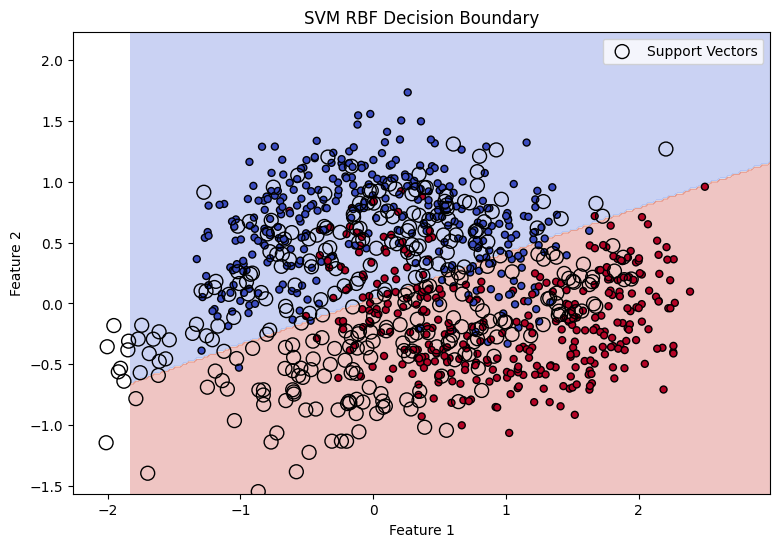

In [5]:
# Создаём двумерный датасет
X_moons, y_moons = make_moons(
    n_samples=700,
    noise=0.25,
    random_state=42
)

# SVM с лучшими найденными параметрами
visual_model = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC(
        kernel="rbf",
        C=grid_search.best_params_["svc__C"],
        gamma=grid_search.best_params_["svc__gamma"]
    ))
])

visual_model.fit(X_moons, y_moons)

# Создаём координатную сетку
x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Предсказываем классы для каждой точки сетки
Z = visual_model.predict(
    np.c_[xx.ravel(), yy.ravel()]
)

Z = Z.reshape(xx.shape)

# Визуализация
plt.figure(figsize=(9, 6))

plt.contourf(
    xx, yy, Z,
    alpha=0.3,
    cmap="coolwarm"
)

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    cmap="coolwarm",
    edgecolors="black",
    s=25
)

# Опорные векторы
support_vectors = visual_model.named_steps["svc"].support_vectors_

plt.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=100,
    facecolors="none",
    edgecolors="black",
    label="Support Vectors"
)

plt.title("SVM RBF Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()